In [16]:
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path

if Path.cwd().name == "notebooks":
    %cd ..

In [17]:
from drums.models.flow_matching import main, sample
from itertools import permutations
import numpy as np
import jax
import jax.numpy as jnp
import jax.random as jr

orderings = jnp.array(list(permutations(range(3))))


def procrustes_error(target, prediction):
    target = target - target.mean(axis=0)

    def ordering_error(ordering):
        candidate = prediction[ordering]
        candidate = candidate - candidate.mean(axis=0)
        u, _, vt = jnp.linalg.svd(candidate.T @ target, full_matrices=False)
        aligned = candidate @ (u @ vt)
        return jnp.mean(
            jnp.linalg.norm(target - aligned, axis=1)
            / jnp.linalg.norm(target, axis=1)
        )

    return jnp.min(jax.vmap(ordering_error)(orderings))


batch_error = jax.jit(jax.vmap(procrustes_error))


def evaluate(model, spectra, vertices, n_draws=4, n_steps=100, seed=123):
    errors = []
    for draw_key in jr.split(jr.PRNGKey(seed), n_draws):
        keys = jr.split(draw_key, len(spectra))
        chunks = []
        for start in range(0, len(spectra), 128):
            stop = start + 128
            predictions = jax.vmap(
                lambda spectrum, key: sample(model, spectrum, key, n_steps=n_steps)
            )(spectra[start:stop], keys[start:stop])
            chunks.append(np.asarray(batch_error(vertices[start:stop], predictions)))
        errors.append(np.concatenate(chunks))
    return np.stack(errors)

In [18]:
model17, history17, spectra17, vertices17 = main(seed=17, canonical=False)

0: train=1.4959, test=1.4909
500: train=0.7081, test=0.6095
1000: train=0.6099, test=0.5828
1500: train=0.6353, test=0.5318
2000: train=0.5298, test=0.5169
2500: train=0.5658, test=0.5328
3000: train=0.4775, test=0.4784
3500: train=0.5199, test=0.4718
4000: train=0.4871, test=0.4680
4500: train=0.4643, test=0.4507


In [19]:
assert spectra17.shape == (1000, 30)
assert vertices17.shape == (1000, 3, 2)
N_DRAWS, N_STEPS = 2, 20

In [20]:
errors17 = evaluate(model17, spectra17, vertices17, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 17:", "train", errors17[:, :900].mean(), "test", errors17[:, 900:].mean())

Seed 17: train 0.11046844 test 0.11587537


In [21]:
model18, history18, spectra18, vertices18 = main(seed=18, canonical=False)

0: train=1.5497, test=1.6419
500: train=0.7979, test=0.6330
1000: train=0.6408, test=0.5875
1500: train=0.5947, test=0.5737
2000: train=0.5337, test=0.5389
2500: train=0.5934, test=0.5174
3000: train=0.5565, test=0.4792
3500: train=0.4690, test=0.4582
4000: train=0.5622, test=0.4079
4500: train=0.4499, test=0.4047


In [22]:
errors18 = evaluate(model18, spectra18, vertices18, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Seed 18:", "train", errors18[:, :900].mean(), "test", errors18[:, 900:].mean())

Seed 18: train 0.11496607 test 0.12695795


In [23]:
# Baseline: log + standardise, AdamW, warmup + cosine, clipping, all orderings.
baseline = {17: (0.0054, 0.0058), 18: (0.0054, 0.0065)}
scores = []
print(f"All-orderings Procrustes error; FM averages {N_DRAWS} draws, {N_STEPS} RK4 steps")
print("seed | FM train | FM test | baseline train | baseline test")
for seed, errors in [(17, errors17), (18, errors18)]:
    train_error, test_error = errors[:, :900].mean(), errors[:, 900:].mean()
    scores.append((train_error, test_error))
    b_train, b_test = baseline[seed]
    print(f"{seed:4d} | {train_error:.4f}   | {test_error:.4f}  | {b_train:.4f}         | {b_test:.4f}")
mean_train, mean_test = np.mean(scores, axis=0)
print(f"mean | {mean_train:.4f}   | {mean_test:.4f}  | 0.0054         | 0.0061")
print("Baseline means above are the rounded values reported in triangle_dataset_experiments.md.")
print("FM test std across sampling draws:",
      {seed: float(errors[:, 900:].mean(axis=1).std(ddof=1))
       for seed, errors in [(17, errors17), (18, errors18)]})

All-orderings Procrustes error; FM averages 2 draws, 20 RK4 steps
seed | FM train | FM test | baseline train | baseline test
  17 | 0.1105   | 0.1159  | 0.0054         | 0.0058
  18 | 0.1150   | 0.1270  | 0.0054         | 0.0065
mean | 0.1127   | 0.1214  | 0.0054         | 0.0061
Baseline means above are the rounded values reported in triangle_dataset_experiments.md.
FM test std across sampling draws: {17: 0.0006711253663524985, 18: 0.007363560143858194}


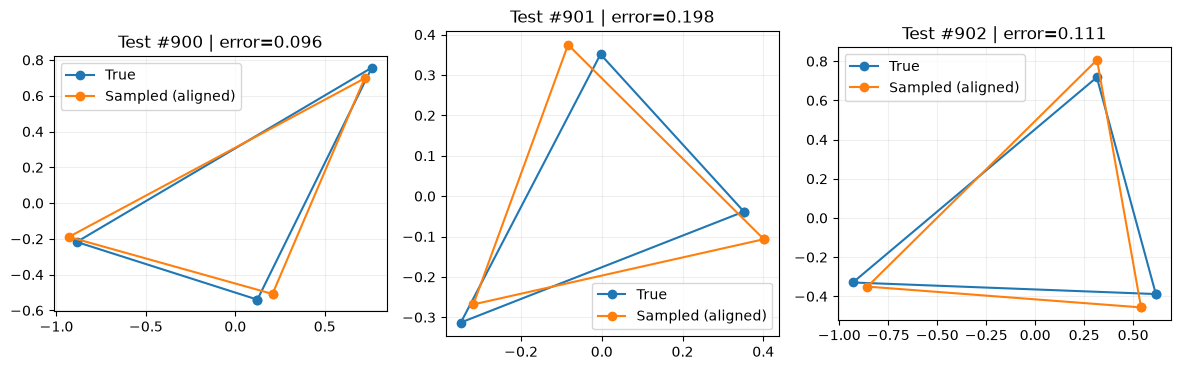

In [24]:
indices = [900, 901, 902]
keys = jr.split(jr.PRNGKey(456), len(indices))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index, key in zip(axes, indices, keys):
    target = np.asarray(vertices17[index])
    target = target - target.mean(axis=0)
    prediction = np.asarray(sample(model17, spectra17[index], key, n_steps=N_STEPS))

    candidates = prediction[np.asarray(orderings)]
    candidates = candidates - candidates.mean(axis=1, keepdims=True)
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target)
    aligned = candidates @ (u @ vt)
    errors = np.mean(
        np.linalg.norm(target - aligned, axis=2)
        / np.linalg.norm(target, axis=1), axis=1
    )
    best = np.argmin(errors)

    for triangle, label in [(target, "True"), (aligned[best], "Sampled (aligned)")]:
        closed = np.vstack([triangle, triangle[0]])
        ax.plot(closed[:, 0], closed[:, 1], "o-", label=label)
    ax.set_title(f"Test #{index} | error={errors[best]:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()

In [25]:
model_c17, history_c17, spectra_c17, vertices_c17 = main(seed=17, canonical=True)
errors_c17 = evaluate(model_c17, spectra_c17, vertices17, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Canonical seed 17:", "train", errors_c17[:, :900].mean(), "test", errors_c17[:, 900:].mean())

0: train=1.4252, test=1.3770
500: train=0.1543, test=0.1108
1000: train=0.1038, test=0.0831
1500: train=0.0909, test=0.0535
2000: train=0.0684, test=0.0589
2500: train=0.0855, test=0.0498
3000: train=0.0367, test=0.0294
3500: train=0.0348, test=0.0275
4000: train=0.0210, test=0.0197
4500: train=0.0197, test=0.0135
Canonical seed 17: train 0.023181783 test 0.024425242


In [26]:
model_c18, history_c18, spectra_c18, vertices_c18 = main(seed=18, canonical=True)
errors_c18 = evaluate(model_c18, spectra_c18, vertices18, n_draws=N_DRAWS, n_steps=N_STEPS)
print("Canonical seed 18:", "train", errors_c18[:, :900].mean(), "test", errors_c18[:, 900:].mean())

0: train=1.5704, test=1.6499
500: train=0.0999, test=0.1631
1000: train=0.0713, test=0.0708
1500: train=0.0522, test=0.0535
2000: train=0.0665, test=0.0487
2500: train=0.0234, test=0.0448
3000: train=0.0359, test=0.0255
3500: train=0.0139, test=0.0245
4000: train=0.0224, test=0.0143
4500: train=0.0054, test=0.0109
Canonical seed 18: train 0.022355385 test 0.022642031


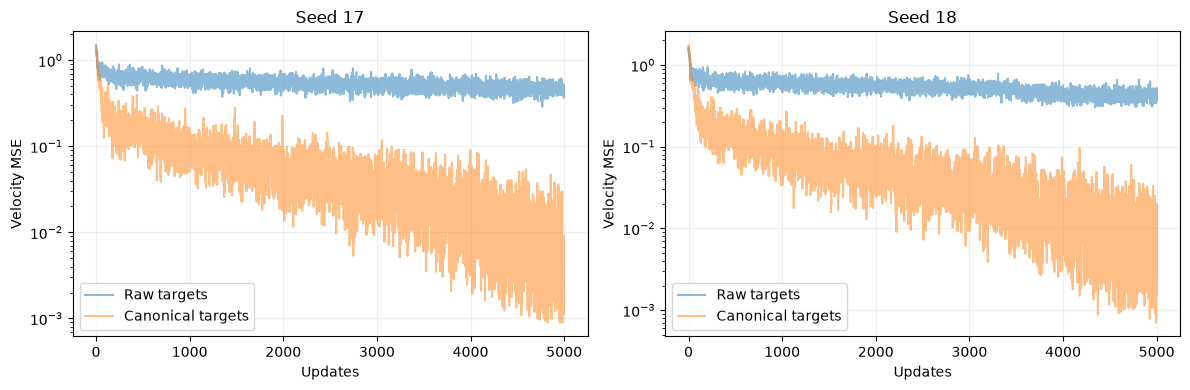

Same evaluation: 2 draws per drum, 20 RK4 steps, 900/100 split
seed | raw train | raw test | canonical train | canonical test | baseline test
  17 | 0.1105 | 0.1159 | 0.0232 | 0.0244 | 0.0058
  18 | 0.1150 | 0.1270 | 0.0224 | 0.0226 | 0.0065
mean | 0.1127 | 0.1214 | 0.0228 | 0.0235 | 0.0061


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, seed, raw_history, canonical_history in [
    (axes[0], 17, history17, history_c17),
    (axes[1], 18, history18, history_c18),
]:
    ax.plot(raw_history, alpha=0.5, label="Raw targets")
    ax.plot(canonical_history, alpha=0.5, label="Canonical targets")
    ax.set(title=f"Seed {seed}", xlabel="Updates", ylabel="Velocity MSE", yscale="log")
    ax.legend()
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

print(f"Same evaluation: {N_DRAWS} draws per drum, {N_STEPS} RK4 steps, 900/100 split")
print("seed | raw train | raw test | canonical train | canonical test | baseline test")
rows = []
for seed, raw, canonical in [(17, errors17, errors_c17), (18, errors18, errors_c18)]:
    scores = [raw[:, :900].mean(), raw[:, 900:].mean(),
              canonical[:, :900].mean(), canonical[:, 900:].mean()]
    rows.append(scores)
    print(f"{seed:4d} | " + " | ".join(f"{score:.4f}" for score in scores)
          + f" | {baseline[seed][1]:.4f}")
print("mean | " + " | ".join(f"{score:.4f}" for score in np.mean(rows, axis=0)) + " | 0.0061")

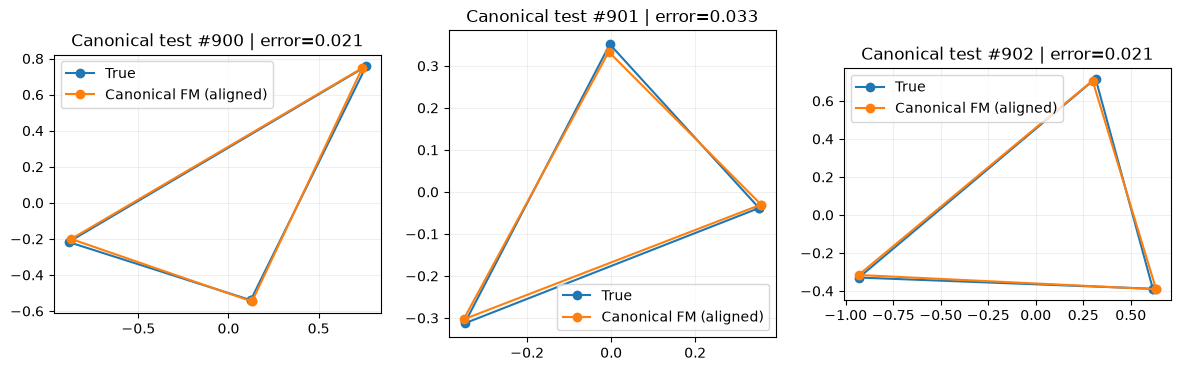

In [28]:
indices = [900, 901, 902]
keys = jr.split(jr.PRNGKey(456), len(indices))
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, index, key in zip(axes, indices, keys):
    target = np.asarray(vertices17[index])
    target = target - target.mean(axis=0)
    prediction = np.asarray(sample(model_c17, spectra_c17[index], key, n_steps=N_STEPS))

    candidates = prediction[np.asarray(orderings)]
    candidates = candidates - candidates.mean(axis=1, keepdims=True)
    u, _, vt = np.linalg.svd(candidates.transpose(0, 2, 1) @ target)
    aligned = candidates @ (u @ vt)
    errors = np.mean(
        np.linalg.norm(target - aligned, axis=2)
        / np.linalg.norm(target, axis=1), axis=1
    )
    best = np.argmin(errors)

    for triangle, label in [(target, "True"), (aligned[best], "Canonical FM (aligned)")]:
        closed = np.vstack([triangle, triangle[0]])
        ax.plot(closed[:, 0], closed[:, 1], "o-", label=label)
    ax.set_title(f"Canonical test #{index} | error={errors[best]:.3f}")
    ax.set_aspect("equal")
    ax.grid(alpha=0.2)
    ax.legend()

plt.tight_layout()
plt.show()